In [61]:
# 1. Install dependencies (Google Colab)
# Run this only when the environment does not already contain these packages.
# %pip install -q torch torchvision scikit-learn pandas numpy matplotlib pillow tqdm opencv-python

# 2. Imports
import copy
import json
import math
import os
import random
import time
import warnings
from pathlib import Path
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_recall_fscore_support, cohen_kappa_score, mean_absolute_error,
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.filterwarnings('ignore', category=UserWarning)
print('Imports completed.')

Imports completed.


# 3. Experiment configuration

Change values in the next cell before running the model. Training and ablation experiments are disabled by default.

In [82]:
CONFIG = {
    'dataset_path': './Dataset',
    'metadata_path': './details.csv',
    'results_path': './cs_mon_results',
    'image_size': 224,
    'batch_size': 16,
    'epochs': 30,
    'learning_rate': 1e-4,
    'weight_decay': 1e-4,
    'num_workers': 0,
    'num_classes': 3,
    'class_names': ['Low', 'Medium', 'High'],
    'sweet_names': ['Kesari', 'Muscat', 'Boondhi'],
    'use_pretrained': True,
    'use_hsv': True,
    'use_lab': True,
    'use_color_gate': True,
    'use_mamba': True,
    'head_type': 'ordinal',
    'confidence_threshold': 0.60,
    'seed': 42,
    'early_stopping_patience': 5,
    'mixed_precision': True,
    'run_training': True,
    'run_ablation': False,
    'ablations_to_run': [],
    'ablation_epochs': 5,
}

print('Configuration loaded.')

Configuration loaded.


# 4. Reproducibility and device setup

In [63]:
SEED = CONFIG['seed']
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('Device:', DEVICE)
print('CUDA available:', torch.cuda.is_available())

Device: cpu
CUDA available: False


# 5. Dataset and results paths

For Google Colab, mount Drive manually if required and change `CONFIG['dataset_path']` and `CONFIG['metadata_path']` to the Drive locations.

In [64]:
ROOT = Path.cwd()
DATASET_PATH = (ROOT / CONFIG['dataset_path']).resolve()
METADATA_PATH = (ROOT / CONFIG['metadata_path']).resolve()
RESULTS_DIR = (ROOT / CONFIG['results_path']).resolve()
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print('Dataset path:', DATASET_PATH)
print('Metadata path:', METADATA_PATH)
print('Results path:', RESULTS_DIR)
print('Training enabled:', CONFIG['run_training'])

Dataset path: D:\SLIIT (4th Year)\RP\Dataset\Dataset
Metadata path: D:\SLIIT (4th Year)\RP\Dataset\details.csv
Results path: D:\SLIIT (4th Year)\RP\Dataset\cs_mon_results
Training enabled: True


# 6. Dataset metadata, validation, and leakage-aware splitting

The loader supports either a metadata CSV or the folder layout `sweet_type/intensity/image`. If `batch_id` or `sample_id` exists, group-based splitting keeps related images together. Otherwise, the notebook warns and uses a stratified fallback.

In [65]:
# 6.1 Metadata helper functions
def find_column(frame, candidates):
    lookup = {str(column).strip().lower(): column for column in frame.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

def build_metadata():
    if METADATA_PATH.exists():
        frame = pd.read_csv(METADATA_PATH)
        path_column = find_column(frame, ['image_path', 'image', 'image name', 'id', 'name'])
        sweet_column = find_column(frame, ['sweet_type', 'food', 'sweet', 'type'])
        level_column = find_column(frame, ['intensity', 'colouring level', 'coloring level', 'level'])
        if not all([path_column, sweet_column, level_column]):
            raise ValueError('Metadata needs image path, sweet type, and intensity columns.')
        frame = frame.rename(columns={path_column: 'image_path', sweet_column: 'sweet_type', level_column: 'intensity'})
        frame['image_path'] = frame['image_path'].astype(str).map(
            lambda value: Path(value) if Path(value).is_absolute() else DATASET_PATH / value
        )
        frame['image_path'] = frame['image_path'].map(
            lambda path: path if path.suffix else path.with_suffix('.jpg')
        )
    else:
        if not DATASET_PATH.exists():
            raise FileNotFoundError(f'Dataset folder not found: {DATASET_PATH}')
        records = []
        for path in DATASET_PATH.rglob('*'):
            if path.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}:
                relative = path.relative_to(DATASET_PATH).parts
                if len(relative) >= 3:
                    records.append({'image_path': path, 'sweet_type': relative[0].title(), 'intensity': relative[1].title()})
        frame = pd.DataFrame(records)
    frame['image_path'] = frame['image_path'].map(Path)
    frame = frame[frame['image_path'].map(Path.exists)].copy()
    frame['sweet_type'] = frame['sweet_type'].astype(str).str.strip().str.title()
    frame['intensity'] = frame['intensity'].astype(str).str.strip().str.title()
    frame = frame[frame['intensity'].isin(CONFIG['class_names'])].reset_index(drop=True)
    frame['level_id'] = frame['intensity'].map({name: index for index, name in enumerate(CONFIG['class_names'])})
    frame['sweet_id'] = pd.Categorical(frame['sweet_type']).codes
    return frame

# 6.2 Load and validate image metadata

In [66]:
metadata = build_metadata()
original_image_count = len(metadata)
valid_rows = []
for index, path in enumerate(metadata['image_path']):
    try:
        with Image.open(path) as image:
            image.verify()
        valid_rows.append(index)
    except Exception:
        pass
metadata = metadata.iloc[valid_rows].reset_index(drop=True)
metadata['stratify_key'] = metadata['sweet_type'] + '_' + metadata['intensity']
print('Total valid images:', len(metadata))
print('Columns:', list(metadata.columns))
print('Removed corrupted or missing images:', original_image_count - len(metadata))

Total valid images: 1296
Columns: ['image_path', 'sweet_type', 'Phone', 'Light', 'Coloring', 'intensity', 'level_id', 'sweet_id', 'stratify_key']
Removed corrupted or missing images: 0


# 6.3 Dataset distribution tables and visual audit

Images per sweet:


,count
sweet_type,
Kesari,648
Mascut,648


Images per intensity:


,count
intensity,
Low,432
Medium,432
High,432


Sweet x intensity:


intensity,Low,Medium,High
sweet_type,,,
Kesari,216,216,216
Mascut,216,216,216


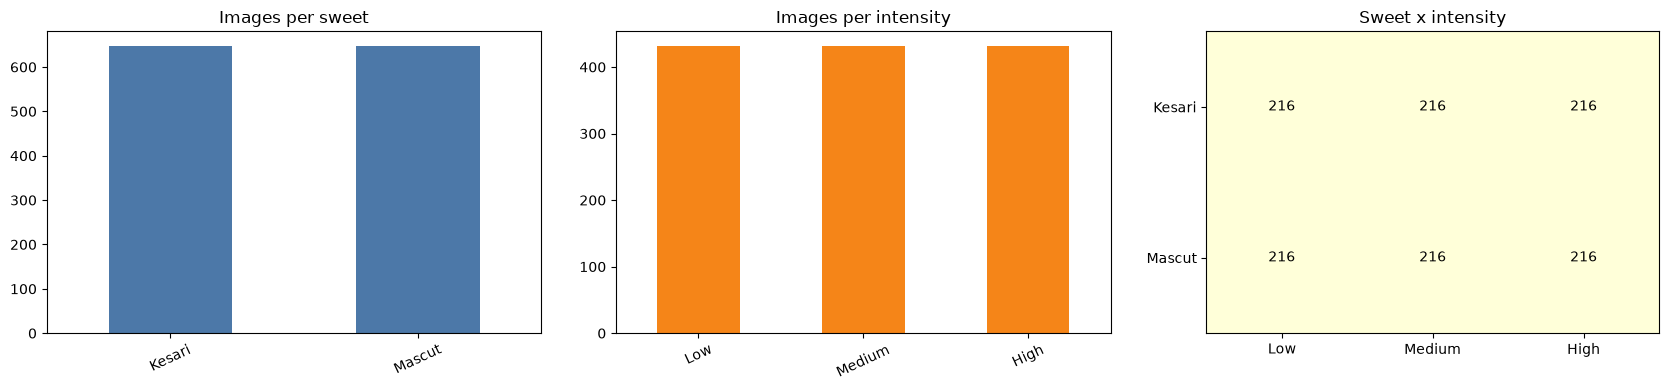

In [67]:
sweet_counts = metadata['sweet_type'].value_counts().sort_index()
level_counts = metadata['intensity'].value_counts().reindex(CONFIG['class_names'], fill_value=0)
distribution_table = pd.crosstab(metadata['sweet_type'], metadata['intensity']).reindex(columns=CONFIG['class_names'], fill_value=0)
print('Images per sweet:'); display(sweet_counts.to_frame('count'))
print('Images per intensity:'); display(level_counts.to_frame('count'))
print('Sweet x intensity:'); display(distribution_table)

figure, axes = plt.subplots(1, 3, figsize=(17, 4))
sweet_counts.plot(kind='bar', ax=axes[0], color='#4C78A8', title='Images per sweet')
level_counts.plot(kind='bar', ax=axes[1], color='#F58518', title='Images per intensity')
axes[2].imshow(distribution_table.to_numpy(), cmap='YlGnBu')
axes[2].set_title('Sweet x intensity')
axes[2].set_xticks(range(len(CONFIG['class_names'])), CONFIG['class_names'])
axes[2].set_yticks(range(len(distribution_table.index)), distribution_table.index)
for row in range(distribution_table.shape[0]):
    for column in range(distribution_table.shape[1]):
        axes[2].text(column, row, distribution_table.iloc[row, column], ha='center', va='center')
for axis in axes[:2]:
    axis.set_xlabel(''); axis.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

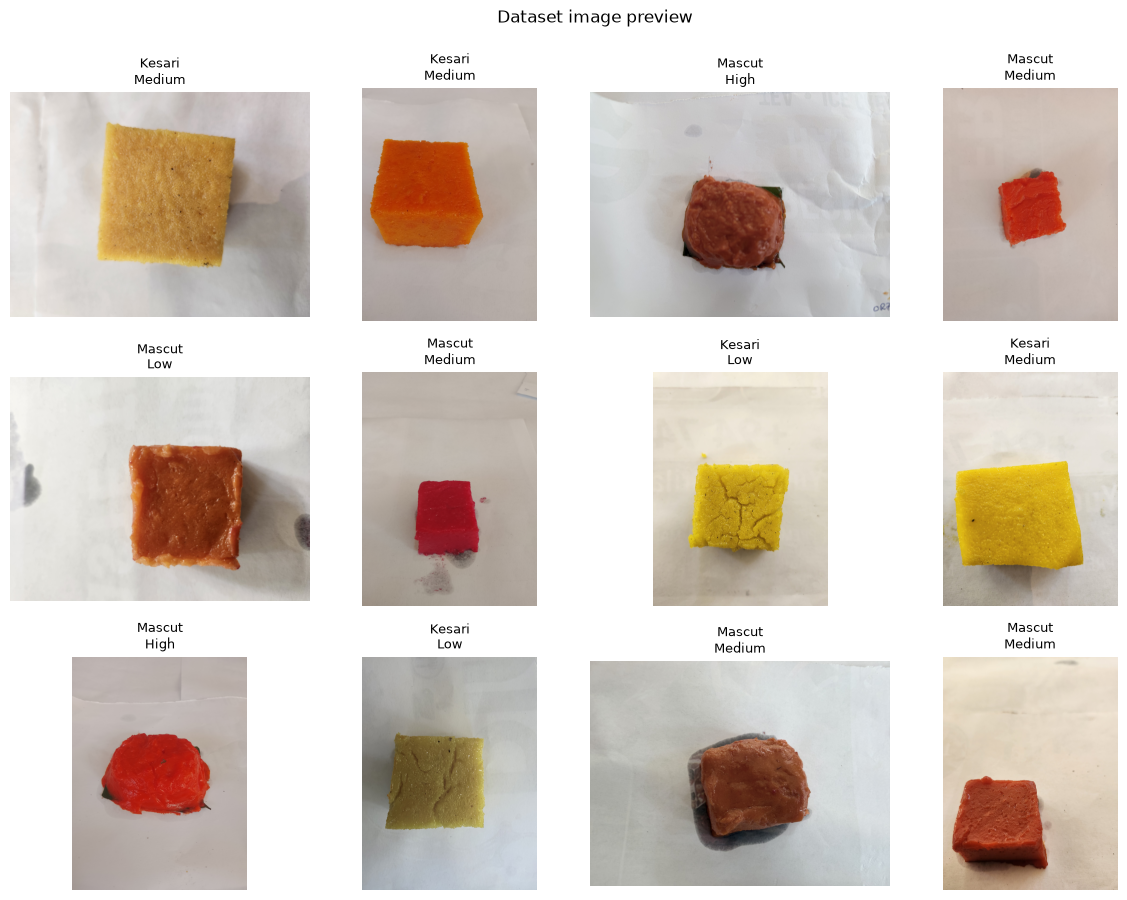

In [68]:
# Preview representative images from the available labels.
preview = metadata.sample(min(12, len(metadata)), random_state=SEED).reset_index(drop=True)
figure, axes = plt.subplots(3, 4, figsize=(12, 9)); axes = axes.flatten()
for axis, (_, row) in zip(axes, preview.iterrows()):
    try:
        axis.imshow(Image.open(row['image_path']).convert('RGB'))
        axis.set_title(f"{row['sweet_type']}\n{row['intensity']}", fontsize=9)
    except Exception:
        axis.set_title('Image unavailable')
    axis.axis('off')
for axis in axes[len(preview):]: axis.axis('off')
plt.suptitle('Dataset image preview', y=0.995)
plt.tight_layout(); plt.show()

# 6.4 Leakage-aware train, validation, and test split

In [69]:
available_group = next((column for column in ['batch_id', 'sample_id'] if column in metadata.columns), None)
if available_group:
    groups = metadata[available_group].fillna(metadata['image_path'].astype(str)).astype(str)
    first_split = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
    train_index, temporary_index = next(first_split.split(metadata, groups=groups))
    temporary = metadata.iloc[temporary_index].copy()
    temporary_groups = groups.iloc[temporary_index]
    second_split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
    validation_index, test_index = next(second_split.split(temporary, groups=temporary_groups))
    train_df = metadata.iloc[train_index].reset_index(drop=True)
    validation_df = temporary.iloc[validation_index].reset_index(drop=True)
    test_df = temporary.iloc[test_index].reset_index(drop=True)
    print('Group-based split using:', available_group)
else:
    print('WARNING: batch_id/sample_id unavailable; using stratified image split.')
    train_df, temporary = train_test_split(metadata, test_size=0.30, random_state=SEED, stratify=metadata['stratify_key'])
    validation_df, test_df = train_test_split(temporary, test_size=0.50, random_state=SEED, stratify=temporary['stratify_key'])
    train_df, validation_df, test_df = [frame.reset_index(drop=True) for frame in (train_df, validation_df, test_df)]

print(f'Train: {len(train_df)} | Validation: {len(validation_df)} | Test: {len(test_df)}')
for split_name, split_frame in [('Train', train_df), ('Validation', validation_df), ('Test', test_df)]:
    print(f'\n{split_name} distribution:')
    display(pd.crosstab(split_frame['sweet_type'], split_frame['intensity']).reindex(columns=CONFIG['class_names'], fill_value=0))

Train: 907 | Validation: 194 | Test: 195

Train distribution:


intensity,Low,Medium,High
sweet_type,,,
Kesari,151,151,152
Mascut,151,151,151



Validation distribution:


intensity,Low,Medium,High
sweet_type,,,
Kesari,32,33,32
Mascut,32,33,32



Test distribution:


intensity,Low,Medium,High
sweet_type,,,
Kesari,33,32,32
Mascut,33,32,33


# 7-10. Preprocessing, dye-aware augmentation, colour spaces, and DataLoaders

Augmentation changes geometry and exposure only. Strong hue or saturation changes are intentionally excluded because the target is visual colour intensity.

In [70]:
# 7.1 Preprocessing and dye-aware augmentation
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.RandomPerspective(distortion_scale=0.08, p=0.25),
    transforms.ColorJitter(brightness=0.12, contrast=0.12),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.ToTensor(),
    transforms.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
])
print('Transforms created. Hue and saturation are intentionally unchanged.')

# 8. Dataset and DataLoaders
class SweetImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        try:
            image = Image.open(row['image_path']).convert('RGB')
        except Exception as error:
            raise RuntimeError(f'Could not read {row["image_path"]}: {error}')
        return {
            'image': self.transform(image),
            'level': torch.tensor(int(row['level_id']), dtype=torch.long),
            'sweet': torch.tensor(int(row['sweet_id']), dtype=torch.long),
            'index': torch.tensor(index, dtype=torch.long),
        }

train_loader = DataLoader(SweetImageDataset(train_df, train_transform), CONFIG['batch_size'], shuffle=True, num_workers=CONFIG['num_workers'], pin_memory=torch.cuda.is_available())
validation_loader = DataLoader(SweetImageDataset(validation_df, eval_transform), CONFIG['batch_size'], shuffle=False, num_workers=CONFIG['num_workers'])
test_loader = DataLoader(SweetImageDataset(test_df, eval_transform), CONFIG['batch_size'], shuffle=False, num_workers=CONFIG['num_workers'])
print('Train batches:', len(train_loader), '| Test batches:', len(test_loader))

Transforms created. Hue and saturation are intentionally unchanged.
Train batches: 57 | Test batches: 13


# 9. RGB, HSV, and LAB colour-space representation

In [71]:
class MultiColorSpaceRepresentation(nn.Module):
    def forward(self, normalized_rgb):
        mean = normalized_rgb.new_tensor(NORMALIZE_MEAN).view(1, 3, 1, 1)
        std = normalized_rgb.new_tensor(NORMALIZE_STD).view(1, 3, 1, 1)
        rgb = (normalized_rgb * std + mean).clamp(0, 1)
        return torch.cat([rgb, self.rgb_to_hsv(rgb), self.rgb_to_lab(rgb)], dim=1)

    @staticmethod
    def rgb_to_hsv(rgb):
        red, green, blue = rgb.unbind(1)
        maximum, minimum = rgb.max(1).values, rgb.min(1).values
        delta = (maximum - minimum).clamp_min(1e-6)
        hue = torch.zeros_like(maximum)
        hue = torch.where(maximum == red, ((green - blue) / delta) % 6, hue)
        hue = torch.where(maximum == green, (blue - red) / delta + 2, hue)
        hue = torch.where(maximum == blue, (red - green) / delta + 4, hue)
        saturation = torch.where(maximum > 0, (maximum - minimum) / maximum.clamp_min(1e-6), torch.zeros_like(maximum))
        return torch.stack([(hue / 6) % 1, saturation, maximum], 1)

    @staticmethod
    def rgb_to_lab(rgb):
        linear = torch.where(rgb > 0.04045, ((rgb + 0.055) / 1.055).pow(2.4), rgb / 12.92)
        matrix = rgb.new_tensor([[0.4124564, 0.3575761, 0.1804375], [0.2126729, 0.7151520, 0.0721750], [0.0193339, 0.1191920, 0.9503041]])
        xyz = torch.einsum('ij,bjhw->bihw', matrix, linear)
        reference = rgb.new_tensor([0.95047, 1.0, 1.08883]).view(1, 3, 1, 1)
        ratio, delta = xyz / reference, 6 / 29
        transformed = torch.where(ratio > delta ** 3, ratio.pow(1 / 3), ratio / (3 * delta ** 2) + 4 / 29)
        return torch.stack([(116 * transformed[:, 1] - 16) / 100, (500 * (transformed[:, 0] - transformed[:, 1]) + 128) / 255, (200 * (transformed[:, 1] - transformed[:, 2]) + 128) / 255], 1).clamp(0, 1)

colour_space_converter = MultiColorSpaceRepresentation()
print('RGB + HSV + LAB representation ready: 9 channels.')

RGB + HSV + LAB representation ready: 9 channels.


# 11-16. Gating, projection, MobileNetV3-Small, Mamba-inspired mixer, and CSMON

The mixer below is self-contained PyTorch code. It is intentionally described as Mamba-inspired/state-space-inspired rather than claiming to be the original Mamba implementation.

In [72]:
# 10. Gated colour-space attention
class ColorSpaceGate(nn.Module):
    def __init__(self, channels=9, reduction=3):
        super().__init__()
        hidden = max(channels // reduction, 4)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.network = nn.Sequential(nn.Linear(channels, hidden), nn.ReLU(), nn.Linear(hidden, channels), nn.Sigmoid())

    def forward(self, x):
        weights = self.network(self.pool(x).flatten(1)).view(x.size(0), x.size(1), 1, 1)
        return x * weights, weights.flatten(1)

print('Learnable 9-channel gate ready.')

Learnable 9-channel gate ready.


# 11. Mamba-inspired spatial feature mixer

In [73]:
class LightweightMambaBlock(nn.Module):
    def __init__(self, dim, expansion=2, conv_kernel=3):
        super().__init__()
        hidden = dim * expansion
        self.norm = nn.LayerNorm(dim)
        self.in_projection = nn.Linear(dim, hidden * 2)
        self.depthwise_conv = nn.Conv1d(hidden, hidden, conv_kernel, padding=conv_kernel // 2, groups=hidden)
        self.state_decay = nn.Parameter(torch.zeros(hidden))
        self.state_input = nn.Linear(hidden, hidden)
        self.out_projection = nn.Linear(hidden, dim)

    def forward(self, x):
        residual = x
        content, gate = self.in_projection(self.norm(x)).chunk(2, dim=-1)
        content = self.depthwise_conv(content.transpose(1, 2)).transpose(1, 2)
        state = torch.zeros_like(content[:, 0])
        outputs = []
        decay = torch.sigmoid(self.state_decay)
        for step in range(content.size(1)):
            state = decay * state + (1 - decay) * torch.tanh(self.state_input(content[:, step]))
            outputs.append(state)
        mixed = torch.stack(outputs, dim=1) * torch.sigmoid(gate)
        return residual + self.out_projection(mixed)

class MambaFeatureMixer(nn.Module):
    def __init__(self, dim, depth=2):
        super().__init__()
        self.blocks = nn.ModuleList([LightweightMambaBlock(dim) for _ in range(depth)])

    def forward(self, tokens):
        for block in self.blocks:
            tokens = block(tokens)
        return tokens

print('Mamba-inspired token mixer ready.')

Mamba-inspired token mixer ready.


# 12-16. Ordinal head, MobileNetV3 backbone, and complete CS-MON

In [74]:
class OrdinalHead(nn.Module):
    def __init__(self, feature_dim, class_count=3, head_type='ordinal'):
        super().__init__()
        self.head_type = head_type
        self.output = nn.Linear(feature_dim, class_count - 1 if head_type == 'ordinal' else class_count)

    def forward(self, features):
        return self.output(features)

class CSMON(nn.Module):
    def __init__(self, class_count=3, use_gate=True, use_mamba=True, head_type='ordinal', pretrained=True):
        super().__init__()
        self.use_gate, self.use_mamba, self.head_type = use_gate, use_mamba, head_type
        self.colour_spaces = MultiColorSpaceRepresentation()
        self.color_gate = ColorSpaceGate(9) if use_gate else nn.Identity()
        self.projection = nn.Sequential(nn.Conv2d(9, 3, 1), nn.BatchNorm2d(3), nn.ReLU(inplace=True))
        try:
            weights = models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
            backbone = models.mobilenet_v3_small(weights=weights)
        except Exception as error:
            warnings.warn(f'Pretrained weights unavailable; using random initialization: {error}')
            backbone = models.mobilenet_v3_small(weights=None)
        self.backbone = backbone.features
        with torch.no_grad():
            probe = self.backbone(torch.zeros(1, 3, CONFIG['image_size'], CONFIG['image_size']))
        self.feature_dim = probe.shape[1]
        self.mixer = MambaFeatureMixer(self.feature_dim, depth=2) if use_mamba else nn.Identity()
        self.head = OrdinalHead(self.feature_dim, class_count, head_type)

    def forward(self, images, return_details=True):
        colour = self.colour_spaces(images)
        gated, gate_weights = self.color_gate(colour) if self.use_gate else (colour, images.new_ones(images.size(0), 9))
        projected = self.projection(gated)
        feature_map = self.backbone(projected)
        tokens = feature_map.flatten(2).transpose(1, 2)
        mixed_tokens = self.mixer(tokens)
        features = mixed_tokens.mean(1)
        logits = self.head(features)
        output = {'logits': logits, 'gate_weights': gate_weights, 'feature_map': feature_map, 'tokens': mixed_tokens, 'features': features}
        return output if return_details else logits

def build_model(model_config=None):
    model_config = model_config or {}
    return CSMON(class_count=3, use_gate=model_config.get('use_gate', CONFIG['use_color_gate']), use_mamba=model_config.get('use_mamba', CONFIG['use_mamba']), head_type=model_config.get('head_type', CONFIG['head_type']), pretrained=model_config.get('pretrained', CONFIG['use_pretrained'])).to(DEVICE)

cs_mon = build_model()
print('CS-MON parameters:', sum(parameter.numel() for parameter in cs_mon.parameters()))

CS-MON parameters: 7585691


# 17-22. Ordinal loss, training, early stopping, checkpoints, and curves

Training is disabled by default. Set `CONFIG['run_training'] = True` only after checking the sanity cell.

In [75]:
# 17. Ordinal targets, decoding, and metrics
def create_ordinal_targets(levels):
    return torch.stack([levels >= 1, levels >= 2], dim=1).float()

def decode_output(output, model):
    if getattr(model, 'head_type', 'ordinal') == 'softmax':
        probabilities = torch.softmax(output['logits'], dim=1)
        return probabilities.argmax(1).long(), probabilities
    probabilities = torch.sigmoid(output['logits'])
    return (probabilities >= 0.5).sum(1).long(), probabilities

def output_loss(output, levels, model):
    if getattr(model, 'head_type', 'ordinal') == 'softmax':
        return F.cross_entropy(output['logits'], levels)
    return F.binary_cross_entropy_with_logits(output['logits'], create_ordinal_targets(levels))

def compute_metrics(true_levels, predicted_levels):
    true_levels, predicted_levels = np.asarray(true_levels), np.asarray(predicted_levels)
    errors = np.abs(true_levels - predicted_levels)
    return {
        'accuracy': accuracy_score(true_levels, predicted_levels),
        'macro_f1': f1_score(true_levels, predicted_levels, average='macro', zero_division=0),
        'ordinal_mae': float(errors.mean()),
        'qwk': float(cohen_kappa_score(true_levels, predicted_levels, weights='quadratic')) if len(np.unique(true_levels)) > 1 else np.nan,
        'severe_error_rate': float((errors == 2).mean()),
        'adjacent_error_rate': float((errors == 1).mean()),
    }

# 18-22. Training loop, scheduler, mixed precision, and early stopping

In [76]:
def run_epoch(model, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, true, predicted = 0.0, [], []
    autocast_context = torch.cuda.amp.autocast if (DEVICE.type == 'cuda' and CONFIG['mixed_precision']) else nullcontext
    for batch in tqdm(loader, leave=False):
        images, levels = batch['image'].to(DEVICE), batch['level'].to(DEVICE)
        with autocast_context():
            output = model(images)
            loss = output_loss(output, levels, model)
        if training:
            optimizer.zero_grad(set_to_none=True)
            if scaler is not None:
                scaler.scale(loss).backward(); scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(optimizer); scaler.update()
            else:
                loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); optimizer.step()
        total_loss += loss.item() * len(images)
        predicted.extend(decode_output(output, model)[0].detach().cpu().numpy())
        true.extend(levels.cpu().numpy())
    metrics = compute_metrics(true, predicted); metrics['loss'] = total_loss / max(len(loader.dataset), 1)
    return metrics

def train_model(model, name='cs_mon', epochs=None, patience=None):
    epochs = epochs or CONFIG['epochs']; patience = patience or CONFIG['early_stopping_patience']
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=2, factor=0.5)
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda' and CONFIG['mixed_precision'])
    best_score, wait, history = -np.inf, 0, []
    best_path, last_path = RESULTS_DIR / f'best_{name}.pt', RESULTS_DIR / f'last_{name}.pt'
    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(model, train_loader, optimizer, scaler); validation_metrics = run_epoch(model, validation_loader)
        score = validation_metrics['accuracy']; scheduler.step(score)
        history.append({'epoch': epoch, 'learning_rate': optimizer.param_groups[0]['lr'], **{f'train_{k}': v for k, v in train_metrics.items()}, **{f'val_{k}': v for k, v in validation_metrics.items()}})
        torch.save({'model_state_dict': model.state_dict(), 'config': CONFIG, 'epoch': epoch}, last_path)
        print(f'{name} epoch {epoch}: val accuracy={score:.3f}, val MAE={validation_metrics["ordinal_mae"]:.3f}')
        if score > best_score:
            best_score, wait = score, 0; torch.save({'model_state_dict': model.state_dict(), 'config': CONFIG, 'epoch': epoch}, best_path)
        else:
            wait += 1
            if wait >= patience: print('Early stopping at epoch', epoch); break
    checkpoint = torch.load(best_path, map_location=DEVICE, weights_only=False); model.load_state_dict(checkpoint['model_state_dict'])
    history = pd.DataFrame(history); history.to_csv(RESULTS_DIR / f'{name}_history.csv', index=False)
    return model, history

if CONFIG['run_training']:
    cs_mon, cs_mon_history = train_model(cs_mon, 'cs_mon')
else:
    cs_mon_history = pd.DataFrame(); print('Training skipped. Set CONFIG["run_training"] = True to train.')

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_18492\3488583454.py:27: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda' and CONFIG['mixed_precision'])


cs_mon epoch 1: val accuracy=0.335, val MAE=0.675


cs_mon epoch 2: val accuracy=0.381, val MAE=0.629


cs_mon epoch 3: val accuracy=0.412, val MAE=0.737


In [77]:
# 23. Model sanity check and prediction collection
batch = next(iter(test_loader))
with torch.no_grad():
    sanity = cs_mon(batch['image'].to(DEVICE))
print('Input:', tuple(batch['image'].shape))
print('Colour-space:', tuple(cs_mon.colour_spaces(batch['image'].to(DEVICE)).shape))
print('Projected:', tuple(cs_mon.projection(cs_mon.colour_spaces(batch['image'].to(DEVICE))).shape))
print('Feature map:', tuple(sanity['feature_map'].shape))
print('Tokens:', tuple(sanity['tokens'].shape))
print('Ordinal logits:', tuple(sanity['logits'].shape))
print('Total parameters:', sum(parameter.numel() for parameter in cs_mon.parameters()))
print('Trainable parameters:', sum(parameter.numel() for parameter in cs_mon.parameters() if parameter.requires_grad))

def predict_loader(model, loader):
    levels, predictions, indexes = [], [], []
    model.eval()
    with torch.no_grad():
        for batch in loader:
            output = model(batch['image'].to(DEVICE))
            predictions.extend(decode_output(output, model)[0].cpu().numpy())
            levels.extend(batch['level'].numpy()); indexes.extend(batch['index'].numpy())
    return np.asarray(levels), np.asarray(predictions), np.asarray(indexes)

Input: (16, 3, 224, 224)
Colour-space: (16, 9, 224, 224)
Projected: (16, 3, 224, 224)
Feature map: (16, 576, 7, 7)
Tokens: (16, 49, 576)
Ordinal logits: (16, 2)
Total parameters: 7585691
Trainable parameters: 7585691


# 24-26. Test evaluation, confusion matrix, per-sweet metrics, and gate analysis

{
  "accuracy": 0.4,
  "macro_f1": 0.29150326797385623,
  "ordinal_mae": 0.7487179487179487,
  "qwk": 0.24841293833131806,
  "severe_error_rate": 0.14871794871794872,
  "adjacent_error_rate": 0.4512820512820513
}


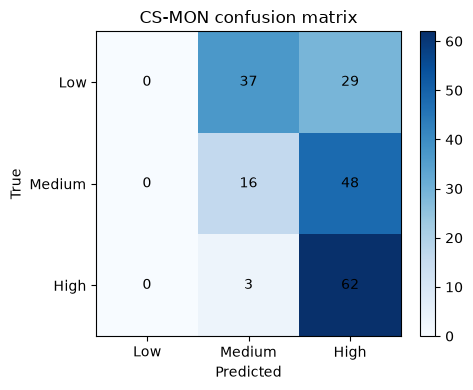

,sweet_type,samples,accuracy,macro_f1,ordinal_mae,qwk,severe_error_rate,adjacent_error_rate
0,Kesari,97,0.329897,0.199520,0.845361,0.203455,0.175258,0.494845
1,Mascut,98,0.469388,0.365079,0.653061,0.301587,0.122449,0.408163


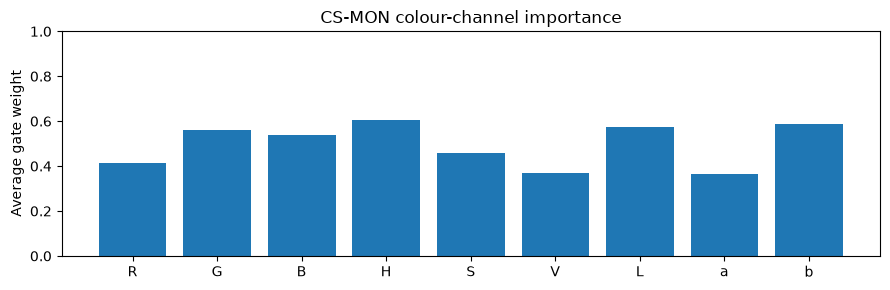

In [78]:
test_metrics = {}
if not cs_mon_history.empty:
    true_levels, predicted_levels, test_indexes = predict_loader(cs_mon, test_loader)
    test_metrics = compute_metrics(true_levels, predicted_levels)
    print(json.dumps(test_metrics, indent=2))
    matrix = confusion_matrix(true_levels, predicted_levels, labels=[0, 1, 2])
    plt.figure(figsize=(5, 4)); plt.imshow(matrix, cmap='Blues'); plt.colorbar()
    plt.xticks([0, 1, 2], CONFIG['class_names']); plt.yticks([0, 1, 2], CONFIG['class_names'])
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('CS-MON confusion matrix')
    for row in range(3):
        for column in range(3): plt.text(column, row, matrix[row, column], ha='center', va='center')
    plt.tight_layout(); plt.savefig(RESULTS_DIR / 'confusion_matrix.png', dpi=160); plt.show()
    test_labels = test_df.iloc[test_indexes].reset_index(drop=True)
    per_sweet = []
    for sweet in sorted(test_labels['sweet_type'].unique()):
        mask = test_labels['sweet_type'].to_numpy() == sweet
        per_sweet.append({'sweet_type': sweet, 'samples': int(mask.sum()), **compute_metrics(true_levels[mask], predicted_levels[mask])})
    per_sweet_df = pd.DataFrame(per_sweet); display(per_sweet_df); per_sweet_df.to_csv(RESULTS_DIR / 'per_sweet_metrics.csv', index=False)
    gate_batches = []
    with torch.no_grad():
        for batch in test_loader: gate_batches.append(cs_mon(batch['image'].to(DEVICE))['gate_weights'].cpu().numpy())
    gate_average = np.concatenate(gate_batches).mean(0)
    plt.figure(figsize=(9, 3)); plt.bar(['R','G','B','H','S','V','L','a','b'], gate_average); plt.ylim(0, 1); plt.ylabel('Average gate weight'); plt.title('CS-MON colour-channel importance'); plt.tight_layout(); plt.savefig(RESULTS_DIR / 'gate_weights.png', dpi=160); plt.show()
else:
    print('Evaluation is ready after training; no fabricated results are displayed.')

In [79]:
# Compatibility helper for the ordinal CS-MON inference and Grad-CAM cells.
def decode_ordinal(logits):
    probabilities = torch.sigmoid(logits)
    return (probabilities >= 0.5).sum(1).long(), probabilities

# 27-34. Grad-CAM, uncertainty, inference, ablations, deployment, and final summary

In [80]:
# 27. Single-image inference, confidence, uncertainty, and Grad-CAM
def enable_dropout(model):
    for module in model.modules():
        if isinstance(module, nn.Dropout): module.train()

def predict_single_image(image_path, sweet_type=None, model=None):
    model = model or cs_mon
    image = Image.open(image_path).convert('RGB')
    tensor = eval_transform(image).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        output = model(tensor); logits = output['logits']
        ordinal_class, threshold_probabilities = decode_ordinal(logits)
        probabilities = torch.sigmoid(logits)
        entropy = -(probabilities * torch.log(probabilities.clamp_min(1e-7)) + (1 - probabilities) * torch.log((1 - probabilities).clamp_min(1e-7))).mean().item()
        confidence = float(1 - entropy / math.log(2))
    result = {'sweet_type': sweet_type, 'predicted_intensity': CONFIG['class_names'][int(ordinal_class.item())], 'class_index': int(ordinal_class.item()), 'confidence': confidence, 'ordinal_score': float(threshold_probabilities.sum().item()), 'entropy': entropy, 'uncertain': confidence < CONFIG['confidence_threshold'], 'screening_notice': 'Image-based screening only; laboratory analysis is required for chemical identity and concentration.'}
    print(result)
    return result

def grad_cam(model, image_tensor, target_class=None):
    target_layer = model.backbone[-1]
    activations, gradients = [], []
    forward_handle = target_layer.register_forward_hook(lambda module, inputs, output: activations.append(output))
    backward_handle = target_layer.register_full_backward_hook(lambda module, grad_input, grad_output: gradients.append(grad_output[0]))
    model.eval(); model.zero_grad(set_to_none=True)
    output = model(image_tensor); logits = output['logits']
    target_class = int(target_class if target_class is not None else decode_ordinal(logits)[0].item())
    logits[:, min(target_class, logits.shape[1] - 1)].sum().backward()
    if not activations or not gradients:
        forward_handle.remove(); backward_handle.remove(); raise RuntimeError('Grad-CAM hooks did not capture tensors.')
    weights = gradients[-1].mean(dim=(2, 3), keepdim=True)
    heatmap = F.relu((weights * activations[-1]).sum(1, keepdim=True))
    heatmap = F.interpolate(heatmap, size=image_tensor.shape[-2:], mode='bilinear', align_corners=False)[0, 0].detach().cpu()
    heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
    forward_handle.remove(); backward_handle.remove()
    return heatmap, logits.detach()

# 28-34. Ablation registry, latency, model saving, and mobile export

In [81]:
ABLATION_REGISTRY = {
    'A0': {'use_gate': False, 'use_mamba': False, 'head_type': 'softmax'},
    'A1': {'use_gate': False, 'use_mamba': False, 'head_type': 'ordinal'},
    'A2': {'use_gate': False, 'use_mamba': False, 'head_type': 'ordinal'},
    'A3': {'use_gate': True, 'use_mamba': False, 'head_type': 'ordinal'},
    'A4': {'use_gate': True, 'use_mamba': True, 'head_type': 'ordinal'},
}

def run_ablation_experiment(name):
    model = build_model(ABLATION_REGISTRY[name])
    model, history = train_model(model, f'ablation_{name}', CONFIG['ablation_epochs'], 2)
    true, predicted, _ = predict_loader(model, test_loader)
    return {'experiment': name, **compute_metrics(true, predicted), 'parameters': sum(p.numel() for p in model.parameters())}

ablation_rows = []
if CONFIG['run_ablation']:
    for ablation_name in CONFIG['ablations_to_run']:
        ablation_rows.append(run_ablation_experiment(ablation_name))
ablation_results = pd.DataFrame(ablation_rows)
display(ablation_results)

# Save model and prepare lightweight deployment artifacts only after training.
def measure_latency(model, loader, repeats=20):
    sample = next(iter(loader))['image'][:1].to(DEVICE); model.eval()
    with torch.no_grad():
        for _ in range(3): model(sample)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        times = []
        for _ in range(repeats):
            start = time.perf_counter(); model(sample)
            if DEVICE.type == 'cuda': torch.cuda.synchronize()
            times.append((time.perf_counter() - start) * 1000)
    return {'mean_ms': float(np.mean(times)), 'std_ms': float(np.std(times)), 'device': str(DEVICE)}

if not cs_mon_history.empty:
    print('Latency:', measure_latency(cs_mon, test_loader))
    torch.save({'state_dict': cs_mon.state_dict(), 'config': CONFIG, 'test_metrics': test_metrics}, RESULTS_DIR / 'cs_mon_final.pt')
    try:
        scripted = torch.jit.trace(cs_mon, batch['image'][:1].to(DEVICE), strict=False)
        scripted.save(str(RESULTS_DIR / 'cs_mon_scripted.pt'))
        print('TorchScript export completed.')
    except Exception as error:
        print('TorchScript export skipped:', error)
    try:
        quantized = torch.quantization.quantize_dynamic(copy.deepcopy(cs_mon).cpu(), {nn.Linear}, dtype=torch.qint8)
        torch.save(quantized.state_dict(), RESULTS_DIR / 'cs_mon_dynamic_quantized.pt')
        print('Dynamic quantization completed for Linear layers.')
    except Exception as error:
        print('Quantization skipped:', error)
else:
    print('Training is not complete; saving and export are waiting.')

summary = {'test_metrics': test_metrics, 'ablation_results': ablation_results.to_dict('records'), 'results_directory': str(RESULTS_DIR), 'screening_warning': 'Visual screening does not chemically identify a dye.'}
with open(RESULTS_DIR / 'final_results.json', 'w', encoding='utf-8') as file:
    json.dump(summary, file, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))

""


Latency: {'mean_ms': 34.30416000005607, 'std_ms': 7.126752223190038, 'device': 'cpu'}


d:\SLIIT (4th Year)\RP\Dataset\.venv\Lib\site-packages\torch\jit\_trace.py:1000: FutureWarning: `torch.jit.trace` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
d:\SLIIT (4th Year)\RP\Dataset\.venv\Lib\site-packages\torch\jit\_trace.py:1139: FutureWarning: `torch.jit.trace_method` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


TorchScript export completed.
Dynamic quantization completed for Linear layers.
{
  "test_metrics": {
    "accuracy": 0.4,
    "macro_f1": 0.29150326797385623,
    "ordinal_mae": 0.7487179487179487,
    "qwk": 0.24841293833131806,
    "severe_error_rate": 0.14871794871794872,
    "adjacent_error_rate": 0.4512820512820513
  },
  "ablation_results": [],
  "results_directory": "D:\\SLIIT (4th Year)\\RP\\Dataset\\cs_mon_results",
  "screening_warning": "Visual screening does not chemically identify a dye."
}


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_18492\2984833526.py:45: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized = torch.quantization.quantize_dynamic(copy.deepcopy(cs_mon).cpu(), {nn.Linear}, dtype=torch.qint8)
